# 02 — Expected behaviour, before alert thresholds

**Question:** Does operating-command context and recent history explain sensor behaviour better than one reference distribution?

We compare frozen medians and central 90% empirical ranges, then investigate a small temporal model only where residual evidence supports it. A residual is **observed minus expected**, in the measurement's units. It is not a fault label, an anomaly probability or a failure probability. Threshold calibration, persistence rules and event evaluation belong in Notebook 03.

February is a **candidate reference**, not verified healthy operation. Two forward comparisons occur inside February; March–May assesses transfer. **No sensor values from June onward are returned by the source reader.** Timestamp timezone, pulse encoding and some signal semantics remain unresolved.

This notebook uses the same verified **2020 UCI MetroPT-3** source as Notebook 01. Reusable calculations live in `baselines.py`; the source dictionary and valve interpretation remain in `metropt.py`. Model choice is explicit, not automated.

In [1]:
from importlib.metadata import version
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from ts_anomaly.metropt import METRICS, fetch_metropt, read_metropt, operating_state, incident_records, sha256_file
from ts_anomaly.assessment import split_development, state_runs, segment_acf
from ts_anomaly.baselines import fit_reference, apply_reference, compare_predictions, completed_bins, lag_features

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
config = json.loads((ROOT / "configs/metropt.json").read_text())
OUTPUT = ROOT / "outputs/metropt_expected"
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": .2})
pd.set_option("display.max_columns", 14)
pd.set_option("display.max_colwidth", 110)

# Support screens are explicit engineering choices, not independent sample counts.
settings = {"min_observations": 100, "min_days": 3, "quantiles": [.05, .5, .95],
            "temporal_target": "Oil_temperature", "temporal_lags": [1, 5],
            "context_lags": [1], "maximum_residual_acf_lag": 120}
STATES = ["load_command", "off_or_unloaded_command"]

## 1. Observations and calendar boundaries

Reference folds fit **1–14 February → assess 15–21 February**, then **1–21 February → assess 22–29 February**. All boundaries are half-open. The full-February fit is used only after 1 March. Historical readings before an assessment boundary may initialize a forecast: that information would have been available then. Future readings never initialize history.

These are modelling design choices. They are not detected change points. See [UCI's first-month suggestion](https://doi.org/10.24432/C5VW3R) and [chronological validation guidance](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-of-time-series-data).

In [2]:
path = fetch_metropt(config["source"], ROOT / "data/metropt")
data, timeline = read_metropt(path, before=config["test_start"])
data["command"] = operating_state(data)
reference, development = split_development(data, config["start"], config["train_end"], config["test_start"])
assert data.timestamp.max() < pd.Timestamp(config["test_start"])
assert not set(METRICS).intersection(timeline.columns)
analogue = [name for name, definition in METRICS.items() if definition.kind == "gauge"]
folds = pd.DataFrame([
    ("February fold 1", "2020-02-01", "2020-02-15", "2020-02-22"),
    ("February fold 2", "2020-02-01", "2020-02-22", "2020-03-01"),
    ("Development", "2020-02-01", "2020-03-01", "2020-06-01"),
], columns=["period", "fit_start", "fit_end", "evaluation_end"])
for column in ["fit_start", "fit_end", "evaluation_end"]:
    folds[column] = pd.to_datetime(folds[column])
folds["fit_rows"] = [data.timestamp.between(row.fit_start, row.fit_end, inclusive="left").sum() for row in folds.itertuples()]
folds["evaluation_rows"] = [data.timestamp.between(row.fit_end, row.evaluation_end, inclusive="left").sum() for row in folds.itertuples()]
display(folds)
print(f"Reference: {len(reference):,}; development: {len(development):,}; timezone unknown.")

,period,fit_start,fit_end,evaluation_end,fit_rows,evaluation_rows
0,February fold 1,2020-02-01,2020-02-15,2020-02-22,103716,56297
1,February fold 2,2020-02-01,2020-02-22,2020-03-01,160013,54837
2,Development,2020-02-01,2020-03-01,2020-06-01,214850,641982


Reference: 214,850; development: 641,982; timezone unknown.


## 2. What the 15 signals mean

Definitions follow the **2020** [UCI dictionary](https://archive.ics.uci.edu/dataset/791/metropt+3+dataset). Interpretations below are hypotheses, not diagnoses. The 2022 paper describes a different release and does not supply our incident labels.

| Signal | Meaning | What a change could indicate / limitation |
|---|---|---|
| TP2 | Compressor pressure (bar) | Compression cycles produce high/low levels; near-zero values can be expected outside loading. |
| TP3 | Pneumatic-panel pressure (bar) | Consumption lowers pressure; compression replenishes it. Faster losses or poor recovery can reflect demand, leakage or reduced effectiveness. |
| H1 | Separator-related pressure (bar) | Switching changes this pressure; evaluate departures alongside commands and other pressures. |
| DV_pressure | Dryer-related pressure drop (bar) | Discharge excursions may be normal. Changed magnitude or duration warrants investigation, not automatic fault labelling. |
| Reservoirs | Stored-air pressure (bar) | Reveals replenishment and loss of stored pressure; compare its level and agreement with TP3. |
| Oil_temperature | Compressor oil temperature (degC) | Reflects recent operation and thermal conditions. An unusual trajectory alone does not establish an oil leak. |
| Motor_current | One motor phase current (A) | Stopped, unloaded and loaded operation differ. Compare current with commands and pressure response. |
| COMP | Intake-valve control | Documented active state means no intake. Commands provide context; they do not prove the machinery responded. |
| DV_eletric | Outlet-valve control | Documented as active during loading. Combined with COMP, defines our two command groups. |
| Towers | Drying-tower selection | Switching behaviour provides context for drying; long states need operational interpretation. |
| MPG | Loading control | Compare with COMP rather than assuming permanent equivalence. |
| LPS | Existing low-pressure indicator | Retain as an alarm comparator, never as independent ground truth or a primary predictor. |
| Pressure_switch | Dryer-discharge indicator | Timing may explain pressure excursions; source semantics do not justify a universal fault rule. |
| Oil_level | Documented oil-level flag | Constant at 1 in February; polarity/interpretation remains unresolved. Do not infer a month-long low-oil fault. |
| Caudal_impulses | Flowmeter pulse-related signal | Exported encoding is unresolved. Do not sum it or infer flow rate/volume. |

**Roles:** seven analogue targets; COMP/DV_eletric command context; other control channels assessed separately; LPS as comparator; oil level and pulse signal retained but not numerically modelled. No arbitrary combinations of all digital channels are created. Off and unloaded remain pooled; current is not used to define the groups used to explain current.

## 3. Overall and command-conditioned reference distributions

For each measurement, the overall expected value is the fitting-period median. The conditional version uses the median within the observed command group. Both use empirical 5th and 95th percentiles. No Gaussian assumption, clipping, imputation or arbitrary division by a tiny scale is used.

A group needs **100 finite observations on at least three recorded days**. These modest support screens prevent single-episode groups being fitted; they are not a statement about effective sample size. Unresolved/unseen groups remain unsupported. Equal quantiles are reported as a collapsed range, not repaired with an invented tolerance.

References operate at native timestamps. Every comparison uses the same observed targets; method-specific availability is reported separately. The seven measurements are kept in their own units.

In [3]:
fit_options = {key: settings[key] for key in ["min_observations", "min_days"]}
references = {}
for fold in folds.itertuples():
    overall = fit_reference(data, analogue, fold.fit_start, fold.fit_end, **fit_options)
    conditional = fit_reference(data, analogue, fold.fit_start, fold.fit_end, context="command", allowed_states=STATES, **fit_options)
    references[fold.period] = {"overall": overall, "command": conditional}
parameters = pd.concat([table.assign(period=period, method=method)
                        for period, methods in references.items() for method, table in methods.items()], ignore_index=True)
parameters.to_csv(OUTPUT / "native_reference_parameters.csv", index=False)
show = parameters.loc[parameters.period.eq("Development") & parameters.method.eq("command")]
display(show[["measurement", "context", "observations", "days", "expected", "lower", "upper", "supported", "collapsed_range"]].round(4))

,measurement,context,observations,days,expected,lower,upper,supported,collapsed_range
63,TP2,load_command,13031,28,9.3920,5.1730,10.3560,True,False
64,TP3,load_command,13031,28,9.1060,8.0480,10.0280,True,False
65,H1,load_command,13031,28,-0.0140,-0.0240,-0.0080,True,False
66,DV_pressure,load_command,13031,28,-0.0180,-0.0220,-0.0140,True,False
67,Reservoirs,load_command,13031,28,9.1060,8.0500,10.0260,True,False
68,Oil_temperature,load_command,13031,28,55.1750,48.7250,60.4125,True,False
69,Motor_current,load_command,13031,28,6.0050,5.1900,6.2500,True,False
70,TP2,off_or_unloaded_command,201817,28,-0.0120,-0.0160,-0.0080,True,False
71,TP3,off_or_unloaded_command,201817,28,8.9280,8.1440,9.8540,True,False
72,H1,off_or_unloaded_command,201817,28,8.9120,8.1320,9.8400,True,False


In [4]:
reports, reasons, residual_acfs = [], [], []
example_predictions = {}
for fold in folds.itertuples():
    evaluation = data.loc[data.timestamp.ge(fold.fit_end) & data.timestamp.lt(fold.evaluation_end)]
    for measurement in analogue:
        predictions = {}
        for method, table in references[fold.period].items():
            frame = apply_reference(evaluation, table, measurement, context="command" if method == "command" else None)
            frame["context"] = evaluation.command.to_numpy()
            frame["calendar_week"] = frame.timestamp.dt.to_period("W-SUN").astype(str)
            predictions[method] = frame
            counts = frame.groupby("status").size().rename("rows").reset_index()
            reasons.append(counts.assign(period=fold.period, measurement=measurement, method=method))
        for grouping, label in [((), "overall"), (("context",), "by_command"), (("calendar_week",), "by_week")]:
            report = compare_predictions(predictions, grouping)
            reports.append(report.assign(period=fold.period, measurement=measurement, summary=label))
        # ACF uses completed regular bins, on exactly the same supported rows.
        common = np.isfinite(predictions["overall"].expected) & np.isfinite(predictions["command"].expected)
        residual_input = evaluation[["timestamp", "entity_id"]].copy()
        for method, frame in predictions.items():
            residual_input[method] = frame.residual.where(common).to_numpy()
        bins = completed_bins(residual_input, list(predictions), min_count=config["minimum_samples_per_bin"], max_interval=config["gap_threshold"])
        for method in predictions:
            continuous = bins.segment.eq(bins.segment.shift())
            acf, info = segment_acf(bins[method].where(continuous), "1min", settings["maximum_residual_acf_lag"])
            residual_acfs.append({"period": fold.period, "measurement": measurement, "method": method,
                                  "lag1": acf.acf.iloc[1] if len(acf) > 1 else np.nan, **info})
        if fold.period == "Development" and measurement in ["TP2", "Oil_temperature"]:
            for method, frame in predictions.items():
                example_predictions[(measurement, method)] = frame.loc[frame.timestamp.lt("2020-03-01 12:00")].copy()
comparison = pd.concat(reports, ignore_index=True)
availability = pd.concat(reasons, ignore_index=True)
acf_summary = pd.DataFrame(residual_acfs)
comparison.to_csv(OUTPUT / "native_comparison.csv", index=False)
availability.to_csv(OUTPUT / "native_availability.csv", index=False)
acf_summary.to_csv(OUTPUT / "native_residual_acf.csv", index=False)
internal = comparison.loc[comparison.summary.eq("overall") & comparison.period.ne("Development")]
display(internal[["period", "measurement", "method", "common", "mae", "bias", "range_coverage", "range_width"]].round(4))

,period,measurement,method,common,mae,bias,range_coverage,range_width
0,February fold 1,TP2,overall,56297,0.4759,0.4746,0.9378,8.7200
1,February fold 1,TP2,command,56297,0.0578,-0.0193,0.9683,0.2817
10,February fold 1,TP3,overall,56297,0.4755,-0.0026,0.9082,1.7500
11,February fold 1,TP3,command,56297,0.4746,-0.0020,0.9061,1.7340
20,February fold 1,H1,overall,56297,0.9095,-0.4062,0.9185,9.8500
21,February fold 1,H1,command,56297,0.4474,0.0013,0.9072,1.6306
30,February fold 1,DV_pressure,overall,56297,0.0050,0.0025,0.9738,0.0080
31,February fold 1,DV_pressure,command,56297,0.0050,0.0025,0.9747,0.0081
40,February fold 1,Reservoirs,overall,56297,0.4750,-0.0025,0.9073,1.7460
41,February fold 1,Reservoirs,command,56297,0.4743,-0.0037,0.9073,1.7339


## 4. Does command context explain the residuals?

MAE measures typical absolute departure in original units. Signed bias reveals systematic under/overprediction. A high range coverage is uninformative without its width. These are descriptive model diagnostics, not false-positive rates. Rows without reported incidents are not certified healthy.

The ACF below concerns **minute means of native residuals on an uninterrupted segment**, not native ten-second innovations. Aggregation changes dependence. Segment start, end and sample count are saved; no IID significance bands or independence claims are made.

,best_relative_change,worst_relative_change
measurement,,
DV_pressure,0.000,0.000
H1,-0.558,-0.508
Motor_current,-0.287,-0.283
Oil_temperature,-0.007,-0.007
Reservoirs,-0.002,-0.002
TP2,-0.886,-0.878
TP3,-0.002,-0.002


,period,measurement,method,lag1,start,end,samples
0,February fold 1,TP2,overall,0.499,2020-02-15 00:02:00,2020-02-17 00:04:00,2883
1,February fold 1,TP2,command,-0.075,2020-02-15 00:02:00,2020-02-17 00:04:00,2883
2,February fold 1,TP3,overall,0.912,2020-02-15 00:02:00,2020-02-17 00:04:00,2883
3,February fold 1,TP3,command,0.910,2020-02-15 00:02:00,2020-02-17 00:04:00,2883
4,February fold 1,H1,overall,0.547,2020-02-15 00:02:00,2020-02-17 00:04:00,2883
5,February fold 1,H1,command,0.924,2020-02-15 00:02:00,2020-02-17 00:04:00,2883
6,February fold 1,DV_pressure,overall,-0.002,2020-02-15 00:02:00,2020-02-17 00:04:00,2883
7,February fold 1,DV_pressure,command,-0.002,2020-02-15 00:02:00,2020-02-17 00:04:00,2883
8,February fold 1,Reservoirs,overall,0.912,2020-02-15 00:02:00,2020-02-17 00:04:00,2883
9,February fold 1,Reservoirs,command,0.910,2020-02-15 00:02:00,2020-02-17 00:04:00,2883


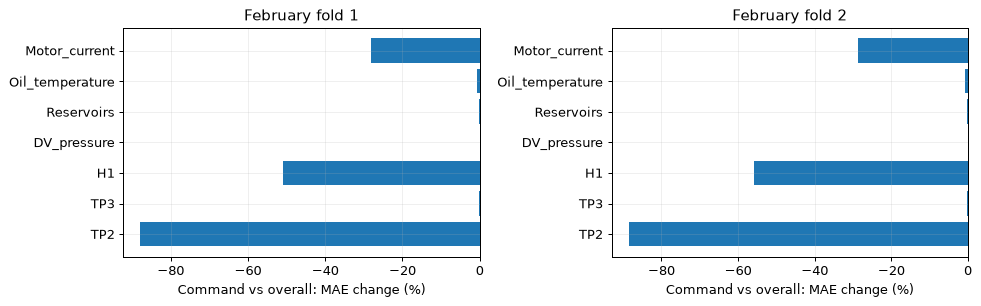

**Observed:** command conditioning reduces MAE in both February folds for H1, Motor_current, Oil_temperature, Reservoirs, TP2, TP3. This is evidence about reference quality, not detector performance. The pooled off/unloaded group may still mix different physical conditions.

In [5]:
internal_mae = internal.pivot(index=["period", "measurement"], columns="method", values="mae")
internal_mae["relative_mae_change"] = (internal_mae.command - internal_mae.overall) / internal_mae.overall
improvement = internal_mae.relative_mae_change.groupby("measurement").agg(["min", "max"])
display(improvement.rename(columns={"min": "best_relative_change", "max": "worst_relative_change"}).round(3))
display(acf_summary.loc[acf_summary.period.ne("Development"), ["period", "measurement", "method", "lag1", "start", "end", "samples"]].round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, period in zip(axes, folds.period.iloc[:2]):
    changes = internal_mae.loc[period, "relative_mae_change"].reindex(analogue)
    ax.barh(changes.index, changes.to_numpy() * 100)
    ax.axvline(0, color="black", linewidth=.7)
    ax.set(title=period, xlabel="Command vs overall: MAE change (%)")
fig.tight_layout(); plt.show()

consistent = improvement.index[improvement['max'].lt(0)].tolist()
display(Markdown(f"**Observed:** command conditioning reduces MAE in both February folds for {', '.join(consistent) or 'no measurement'}. "
                 "This is evidence about reference quality, not detector performance. The pooled off/unloaded group may still mix different physical conditions."))

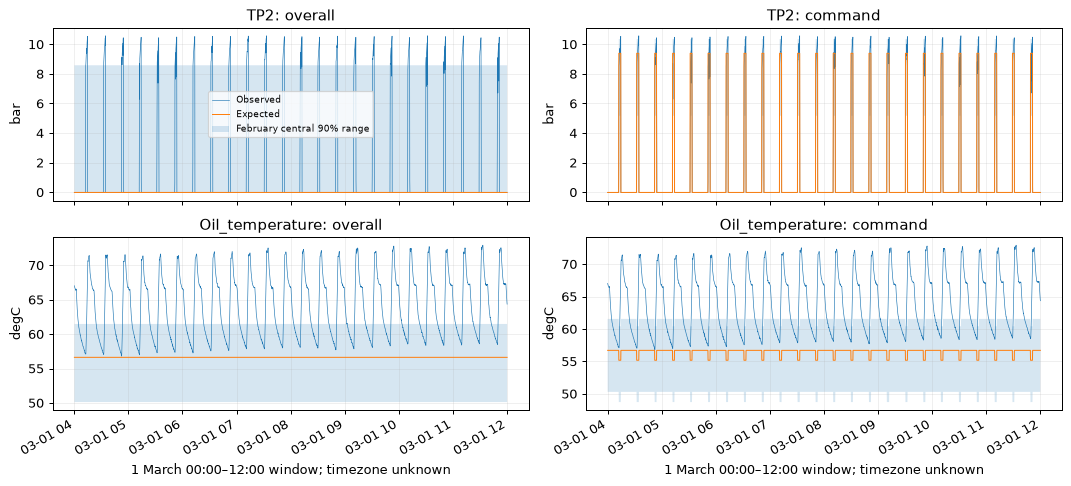

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 5.5), sharex=True)
for row, measurement in enumerate(["TP2", "Oil_temperature"]):
    for ax, method in zip(axes[row], ["overall", "command"]):
        frame = example_predictions[(measurement, method)]
        ax.plot(frame.timestamp, frame.observed, linewidth=.5, label="Observed")
        ax.plot(frame.timestamp, frame.expected, linewidth=.8, label="Expected")
        ax.fill_between(frame.timestamp, frame.lower, frame.upper, alpha=.18, label="February central 90% range")
        ax.set(title=f"{measurement}: {method}", ylabel=METRICS[measurement].unit)
axes[0, 0].legend(fontsize=7)
for ax in axes[-1]:
    ax.set_xlabel("1 March 00:00–12:00 window; timezone unknown")
fig.autofmt_xdate(); fig.tight_layout(); plt.show()

## 5. A targeted recent-history comparison

Oil temperature is the predeclared first candidate because Notebook 01 showed strong persistence. We inspect **out-of-fit command-conditioned residual ACF** before proceeding. This empirical gate is a diagnostic judgement, not a significance test or model selector.

For this comparison alone, the target is a completed one-minute mean. A bin needs at least five observations and cannot straddle a collection break. Unknown commands make the load fraction unavailable. Lags restart after missing bins or source gaps.

We compare a frozen **minute-target February median**, persistence, and one linear model:

\[\widehat T_t=\beta_0+\beta_1T_{t-1}+\beta_5T_{t-5}+\gamma L_{t-1},\]

where \(L\) is the fraction of observed readings under a load command in the preceding completed minute. This is an observation fraction, not exact physical duty time. Period boundaries here refer to when the summary becomes available; the minute ending at a boundary contains earlier readings. The full declared minute grid retains unavailable intervals in coverage denominators. The two temperature lags separate immediate persistence from a short recent trajectory. They are a limited predeclared candidate, not the outcome of a lag search. No coefficient p-values assume independent errors.

The linear model's coefficients remain frozen after fitting. Its inputs update from past readings. Both persistence and the linear model can follow a developing fault; the fixed reference remains alongside them.

In [7]:
target = settings["temporal_target"]
evidence = acf_summary.loc[acf_summary.measurement.eq(target) & acf_summary.method.eq("command") & acf_summary.period.ne("Development")]
display(evidence[["period", "lag1", "samples"]].round(3))
assert evidence.lag1.notna().all() and evidence.lag1.abs().min() > .5, "Reassess whether a temporal model is warranted."
display(Markdown(f"**Observed:** command-conditioned temperature residual lag-one minute ACF is {evidence.lag1.min():.3f}–{evidence.lag1.max():.3f} across the two folds. "
                 "A small history model is therefore worth testing. This threshold records this experiment's rationale, not a generic rule for other datasets."))

inputs = data[["timestamp", "entity_id", target]].copy()
inputs["load_fraction"] = data.command.eq("load_command").astype(float).where(data.command.isin(STATES))
minute = completed_bins(inputs, [target, "load_fraction"], min_count=config["minimum_samples_per_bin"], max_interval=config["gap_threshold"], complete_columns=["load_fraction"])
# Include unavailable leading/trailing minutes in the declared denominator.
minute = minute.reindex(pd.date_range(config["start"], config["test_start"], freq="1min", inclusive="left", name="timestamp"))
minute["entity_id"] = data.entity_id.iloc[0]
minute["context"] = np.select([minute.load_fraction.eq(0), minute.load_fraction.eq(1), minute.load_fraction.between(0, 1, inclusive="neither")],
                               ["off_or_unloaded_command", "load_command", "mixed_command"], default="unavailable")
features = lag_features(minute, {target: (1, 5), "load_fraction": (1,)})
predictors = [f"{target}_lag1", f"{target}_lag5", "load_fraction_lag1"]
design = features[predictors].copy()
design.insert(0, "intercept", 1.)
valid = np.isfinite(design).all(axis=1) & np.isfinite(features[target])
display(pd.Series({"completed_bins": len(features), "observed_target_bins": features[target].notna().sum(),
                   "complete_history_bins": valid.sum()}, name="minutes").to_frame())

,period,lag1,samples
11,February fold 1,0.964,2883
25,February fold 2,0.984,2487


**Observed:** command-conditioned temperature residual lag-one minute ACF is 0.964–0.984 across the two folds. A small history model is therefore worth testing. This threshold records this experiment's rationale, not a generic rule for other datasets.

,minutes
completed_bins,174240
observed_target_bins,142128
complete_history_bins,136521


In [8]:
temporal_reports, temporal_predictions, coefficient_rows = [], {}, []
error_offsets = {}
for fold in folds.itertuples():
    fitting = features.index.to_series().ge(fold.fit_start) & features.index.to_series().lt(fold.fit_end)
    evaluating = features.index.to_series().ge(fold.fit_end) & features.index.to_series().lt(fold.evaluation_end)
    training_rows = fitting & valid
    assert features.index[training_rows].max() < fold.fit_end
    coefficients, _, rank, _ = np.linalg.lstsq(design.loc[training_rows], features.loc[training_rows, target], rcond=None)
    assert rank == design.shape[1]
    coefficient_rows.append({"period": fold.period, "fitting_rows": int(training_rows.sum()), **dict(zip(design.columns, coefficients))})
    # The fixed comparator uses the identical minute target, not native observations.
    quantiles = features.loc[fitting, target].quantile([.05, .5, .95])
    evaluated = features.loc[evaluating]
    base = pd.DataFrame({"timestamp": evaluated.index, "entity_id": evaluated.entity_id.to_numpy(),
                         "observed": evaluated[target].to_numpy(), "context": evaluated.context.to_numpy()})
    base["calendar_week"] = base.timestamp.dt.to_period("W-SUN").astype(str)
    expected = {"fixed_minute": np.full(len(base), quantiles.loc[.5]),
                "persistence": evaluated[f"{target}_lag1"].to_numpy(),
                "linear_history": (design.loc[evaluating] @ coefficients).to_numpy()}
    predictions = {}
    for method, values in expected.items():
        frame = base.assign(expected=values, lower=np.nan, upper=np.nan)
        if method == "fixed_minute":
            frame[["lower", "upper"]] = quantiles.loc[.05], quantiles.loc[.95]
        elif fold.period == "Development":
            # Reference error quantiles come ONLY from the two earlier out-of-fit folds.
            frame["lower"] = frame.expected + error_offsets[method][0]
            frame["upper"] = frame.expected + error_offsets[method][1]
        frame["residual"] = frame.observed - frame.expected
        frame["status"] = np.where(frame.expected.isna(), "missing_history", "available")
        frame.loc[frame.observed.isna(), "status"] = "missing_measurement"
        predictions[method] = frame
    temporal_predictions[fold.period] = predictions
    for grouping, label in [((), "overall"), (("context",), "by_command"), (("calendar_week",), "by_week")]:
        temporal_reports.append(compare_predictions(predictions, grouping).assign(period=fold.period, summary=label))
    if fold.period == "February fold 2":
        for method in ["persistence", "linear_history"]:
            errors = pd.concat([temporal_predictions[period][method].residual for period in folds.period.iloc[:2]])
            error_offsets[method] = errors.quantile([.05, .95]).to_list()

temporal_comparison = pd.concat(temporal_reports, ignore_index=True)
coefficients_table = pd.DataFrame(coefficient_rows)
temporal_comparison.to_csv(OUTPUT / "temporal_comparison.csv", index=False)
coefficients_table.to_csv(OUTPUT / "temporal_coefficients.csv", index=False)
display(coefficients_table.round(5))
display(temporal_comparison.loc[temporal_comparison.summary.eq("overall")].round(4))

,period,fitting_rows,intercept,Oil_temperature_lag1,Oil_temperature_lag5,load_fraction_lag1
0,February fold 1,16989,0.59672,0.96328,0.02363,2.44455
1,February fold 2,26258,0.57364,0.96608,0.02108,2.62639
2,Development,35287,0.59027,0.97836,0.00897,2.09375


,method,requested,available,availability,common,mae,bias,...,range_rows,range_coverage,range_width,period,summary,context,calendar_week
0,fixed_minute,10080,9299,0.9225,9269,2.9317,-1.5691,...,9269,0.8731,11.1673,February fold 1,overall,NaN,NaN
1,persistence,10080,9293,0.9219,9269,0.4427,0.0005,...,0,NaN,NaN,February fold 1,overall,NaN,NaN
2,linear_history,10080,9269,0.9195,9269,0.3047,0.0056,...,0,NaN,NaN,February fold 1,overall,NaN,NaN
21,fixed_minute,11520,9058,0.7863,9029,2.4750,-1.6997,...,9029,0.9241,11.5342,February fold 2,overall,NaN,NaN
22,persistence,11520,9052,0.7858,9029,0.2147,0.0037,...,0,NaN,NaN,February fold 2,overall,NaN,NaN
23,linear_history,11520,9029,0.7838,9029,0.2856,-0.0224,...,0,NaN,NaN,February fold 2,overall,NaN,NaN
42,fixed_minute,132480,106653,0.8050,101234,6.4075,4.7303,...,101234,0.5125,11.2721,Development,overall,NaN,NaN
43,persistence,132480,101925,0.7694,101234,0.9334,0.0012,...,101234,0.5549,1.2662,Development,overall,NaN,NaN
44,linear_history,132480,101234,0.7641,101234,0.7990,-0.1659,...,101234,0.6701,1.4277,Development,overall,NaN,NaN


The temporal reference ranges use empirical **out-of-fit February forecast errors** added to the development predictions. We do not evaluate these ranges on the same errors used to construct them: internal-fold temporal coverage is deliberately blank. Their March–May coverage is descriptive, not a distribution-free guarantee. Normality, independence and stable variance are not assumed.

Native-target errors and minute-target errors are different quantities and are never ranked together. Within the minute experiment, all methods' errors use common eligible targets; availability retains each method's full denominator.

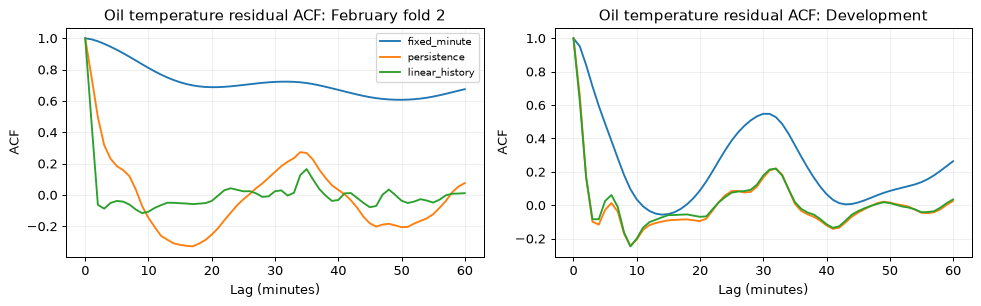

,period,method,lag1,start,end,samples
0,February fold 2,fixed_minute,0.993,2020-02-26 04:30:00,2020-02-27 21:51:00,2482
1,February fold 2,persistence,0.752,2020-02-26 04:30:00,2020-02-27 21:51:00,2482
2,February fold 2,linear_history,0.461,2020-02-26 04:30:00,2020-02-27 21:51:00,2482
3,Development,fixed_minute,0.952,2020-03-24 04:09:00,2020-03-27 05:58:00,4430
4,Development,persistence,0.658,2020-03-24 04:09:00,2020-03-27 05:58:00,4430
5,Development,linear_history,0.622,2020-03-24 04:09:00,2020-03-27 05:58:00,4430


**Observed:** development minute-temperature MAE is 6.408 degC for the fixed reference, 0.933 for persistence and 0.799 for linear history. A small forecast residual does not establish healthy temperature: a persistent level shift can be followed by either history method.

**Decision:** linear history improves MAE in 1/2 February folds; changes are -31.2% and 33.0% versus persistence. Keep persistence as the primary history benchmark; linear history remains a candidate, not an established winner. Development range coverage is 55.5% for persistence and 67.0% for linear history. The empirical February error ranges do not retain 90% coverage in development; wider or newly calibrated alert limits are not selected in this notebook.

In [9]:
temporal_acfs = []
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, period in zip(axes, ["February fold 2", "Development"]):
    predictions = temporal_predictions[period]
    common = np.logical_and.reduce([np.isfinite(frame.expected) & np.isfinite(frame.observed) for frame in predictions.values()])
    for method, frame in predictions.items():
        series = pd.Series(frame.residual.where(common).to_numpy(), index=pd.DatetimeIndex(frame.timestamp))
        acf, info = segment_acf(series, "1min", 60)
        ax.plot(acf.lag_minutes, acf.acf, label=method)
        temporal_acfs.append({"period": period, "method": method, "lag1": acf.acf.iloc[1], **info})
    ax.set(title=f"Oil temperature residual ACF: {period}", xlabel="Lag (minutes)", ylabel="ACF")
axes[0].legend(fontsize=8)
fig.tight_layout(); plt.show()
temporal_acfs = pd.DataFrame(temporal_acfs)
display(temporal_acfs.round(3))
temporal_acfs.to_csv(OUTPUT / "temporal_residual_acf.csv", index=False)

summary = temporal_comparison.loc[temporal_comparison.summary.eq("overall")].pivot(index="period", columns="method", values="mae")
display(Markdown(f"**Observed:** development minute-temperature MAE is {summary.loc['Development', 'fixed_minute']:.3f} degC for the fixed reference, "
                 f"{summary.loc['Development', 'persistence']:.3f} for persistence and {summary.loc['Development', 'linear_history']:.3f} for linear history. "
                 "A small forecast residual does not establish healthy temperature: a persistent level shift can be followed by either history method."))
relative = (summary.linear_history - summary.persistence) / summary.persistence
linear_wins = int(relative.loc[folds.period.iloc[:2]].lt(0).sum())
development_ranges = temporal_comparison.loc[temporal_comparison.period.eq("Development") & temporal_comparison.summary.eq("overall")].set_index("method")
display(Markdown(f"**Decision:** linear history improves MAE in {linear_wins}/2 February folds; changes are {relative.loc['February fold 1']:.1%} and {relative.loc['February fold 2']:.1%} versus persistence. "
                 "Keep persistence as the primary history benchmark; linear history remains a candidate, not an established winner. "
                 f"Development range coverage is {development_ranges.loc['persistence', 'range_coverage']:.1%} for persistence and {development_ranges.loc['linear_history', 'range_coverage']:.1%} for linear history. "
                 "The empirical February error ranges do not retain 90% coverage in development; wider or newly calibrated alert limits are not selected in this notebook."))

## 6. Commands can become abnormal even when conditional sensor values look ordinary

For each calendar month, count transitions only across connected observations. Connected time is the sum of adjacent intervals no larger than 15 seconds. Allocate that time to the preceding recorded command (a piecewise-constant observation convention). Physical switches between samples are unresolved. Unknown commands are reported rather than merged with off/unloaded.

Observed run spans are lower duration bounds; complete runs also have an upper bound from neighbouring transitions. Both collection gaps and month boundaries censor runs. Complete-run quantiles can be biased toward short episodes, so they are descriptive references, not duration thresholds. No eventual episode duration is used as a predictor.

,month,context,connected_hours,state_time_fraction,entries_per_connected_hour,complete_runs,censored_fraction,median_lower_s,median_upper_s
0,2020-02,load_command,591.489,0.061,1.959,1157,0.007,99.0,119.0
1,2020-02,off_or_unloaded_command,591.489,0.939,1.966,1138,0.046,1725.0,1744.5
2,2020-02,unresolved,591.489,0.000,0.003,2,0.000,0.0,20.0
3,2020-03,load_command,634.490,0.172,2.638,1666,0.018,128.0,148.0
4,2020-03,off_or_unloaded_command,634.490,0.827,2.651,1647,0.036,1219.0,1239.0
5,2020-03,unresolved,634.490,0.001,0.009,6,0.143,0.0,20.0
6,2020-04,load_command,553.504,0.149,2.096,1155,0.031,119.0,139.0
7,2020-04,off_or_unloaded_command,553.504,0.808,3.619,1956,0.037,694.0,714.0
8,2020-04,unresolved,553.504,0.043,1.498,828,0.001,0.0,25.0
9,2020-05,load_command,593.300,0.169,2.380,1404,0.034,129.0,149.0


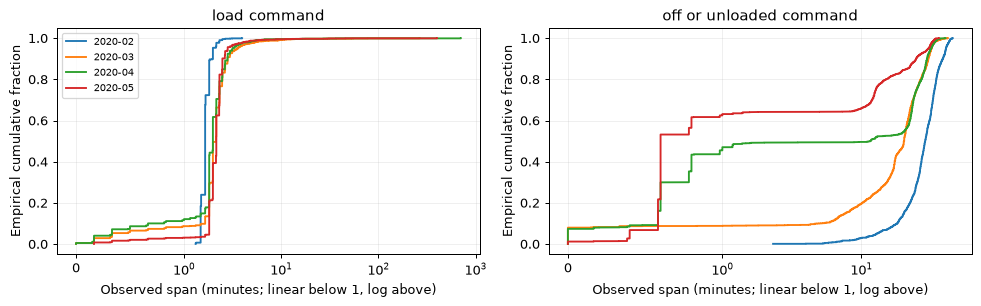

In [10]:
command_records, run_tables = [], []
for month, group in data.groupby(data.timestamp.dt.to_period("M")):
    series = group.set_index("timestamp").command
    runs = state_runs(series, config["gap_threshold"])
    runs["month"] = str(month)
    run_tables.append(runs)
    delta = group.timestamp.diff().dt.total_seconds()
    connected = delta.gt(0) & delta.le(pd.Timedelta(config["gap_threshold"]).total_seconds())
    previous = group.command.shift()
    transitions = connected & group.command.ne(previous)
    for state in [*STATES, "unresolved"]:
        selected = runs.loc[runs.value.eq(state)]
        complete = selected.loc[~selected.left_censored & ~selected.right_censored]
        command_records.append({"month": str(month), "context": state,
            "connected_hours": delta[connected].sum() / 3600,
            "observed_state_hours": delta[connected & previous.eq(state)].sum() / 3600,
            "entries": int((transitions & group.command.eq(state)).sum()),
            "runs": len(selected), "complete_runs": len(complete),
            "censored_fraction": 1 - len(complete) / len(selected) if len(selected) else np.nan,
            "median_lower_s": complete.observed_span_s.median(),
            "median_upper_s": complete.duration_upper_s.median(),
            "p95_lower_s": complete.observed_span_s.quantile(.95)})
commands = pd.DataFrame(command_records)
commands["state_time_fraction"] = commands.observed_state_hours / commands.connected_hours
commands["entries_per_connected_hour"] = commands.entries / commands.connected_hours
runs = pd.concat(run_tables, ignore_index=True)
commands.to_csv(OUTPUT / "command_monthly.csv", index=False)
runs.to_csv(OUTPUT / "command_runs.csv", index=False)
display(commands[["month", "context", "connected_hours", "state_time_fraction", "entries_per_connected_hour", "complete_runs", "censored_fraction", "median_lower_s", "median_upper_s"]].round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, state in zip(axes, STATES):
    for month, group in runs.loc[runs.value.eq(state) & ~runs.left_censored & ~runs.right_censored].groupby("month"):
        values = np.sort(group.observed_span_s.to_numpy() / 60)
        ax.step(values, np.arange(1, len(values) + 1) / len(values), where="post", label=month)
    ax.set(title=state.replace("_", " "), xlabel="Observed span (minutes; linear below 1, log above)", ylabel="Empirical cumulative fraction")
    ax.set_xscale("symlog", linthresh=1)
axes[0].legend(fontsize=8)
fig.tight_layout(); plt.show()

In [11]:
control_records = []
for month, group in data.groupby(data.timestamp.dt.to_period("M")):
    for measurement in ["COMP", "DV_eletric", "Towers", "MPG", "Pressure_switch", "LPS", "Oil_level", "Caudal_impulses"]:
        episodes = state_runs(group.set_index("timestamp")[measurement], config["gap_threshold"])
        control_records.append({"month": str(month), "measurement": measurement,
            "observed_values": group[measurement].nunique(), "fraction_recorded_1": group[measurement].eq(1).mean(),
            "observed_transitions": int((~episodes.left_censored).sum()),
            "COMP_agreement": group[measurement].eq(group.COMP).mean() if measurement == "MPG" else np.nan,
            "role": METRICS[measurement].role})
control_summary = pd.DataFrame(control_records)
control_summary.to_csv(OUTPUT / "digital_monthly.csv", index=False)
display(control_summary.loc[control_summary.measurement.isin(["Towers", "MPG", "Pressure_switch", "LPS", "Oil_level", "Caudal_impulses"])].round(4))
load_time = commands.loc[commands.context.eq("load_command")].set_index("month").state_time_fraction
display(Markdown(f"**Observed:** connected-time loading fraction is {load_time.iloc[0]:.1%} in February and ranges from {load_time.iloc[1:].min():.1%} to {load_time.iloc[1:].max():.1%} across development months. "
                 "This is a change in observed operation, not proof of leakage. Other digital channels remain distinct; new oil/pulse states cannot be interpreted physically until their encoding is resolved."))
unknown = commands.loc[commands.context.eq("unresolved")].set_index("month")
display(Markdown(f"**Context limitation:** unresolved commands occupy {unknown.loc['2020-04', 'state_time_fraction']:.1%} of connected April time and {unknown.loc['2020-05', 'state_time_fraction']:.1%} in May. "
                 "Brief unresolved combinations split otherwise similar command runs. Increased transition counts and shorter off/unloaded spans therefore do not directly measure physical compressor starts or cycle lengths."))

,month,measurement,observed_values,fraction_recorded_1,observed_transitions,COMP_agreement,role
2,2020-02,Towers,2,0.9697,3119,NaN,context
3,2020-02,MPG,2,0.9393,2322,1.0000,context
4,2020-02,Pressure_switch,2,0.9992,324,NaN,context
5,2020-02,LPS,2,0.0000,1,NaN,existing_alarm
6,2020-02,Oil_level,1,1.0000,0,NaN,unresolved
7,2020-02,Caudal_impulses,1,1.0000,0,NaN,unresolved
10,2020-03,Towers,2,0.9137,8173,NaN,context
11,2020-03,MPG,2,0.8274,3358,0.9995,context
12,2020-03,Pressure_switch,2,0.9963,1670,NaN,context
13,2020-03,LPS,2,0.0024,24,NaN,existing_alarm


**Observed:** connected-time loading fraction is 6.1% in February and ranges from 14.9% to 17.2% across development months. This is a change in observed operation, not proof of leakage. Other digital channels remain distinct; new oil/pulse states cannot be interpreted physically until their encoding is resolved.

**Context limitation:** unresolved commands occupy 4.3% of connected April time and 1.5% in May. Brief unresolved combinations split otherwise similar command runs. Increased transition counts and shorter off/unloaded spans therefore do not directly measure physical compressor starts or cycle lengths.

## 7. Pressure agreement is complementary to pressure level

TP3 and Reservoirs almost coincide in February. Fit their **difference** directly, using a February median and central 90% range. This avoids pretending they are independent evidence or fitting an unnecessary multivariate model. A shared pressure loss can leave the difference unchanged; retain each original pressure signal.

,expected,lower,upper,observations
0,-0.002,-0.006,0.002,214850


,month,method,requested,available,availability,common,mae,bias,residual_sd,p90_absolute_error,range_rows,range_coverage,range_width
0,2020-03,difference,230448,230448,1.0,230448,0.00290,0.00265,0.00246,0.006,230448,0.83962,0.008
1,2020-04,difference,198734,198734,1.0,198734,0.00204,0.00169,0.00212,0.004,198734,0.94271,0.008
2,2020-05,difference,212800,212800,1.0,212800,0.00185,0.00110,0.00236,0.004,212800,0.94324,0.008


**Observed:** February's median TP3–Reservoirs difference is -0.0020 bar. Development mean residuals range from 0.0011 to 0.0027 bar. These small offsets deserve calibration/measurement interpretation; near-perfect agreement cannot establish fault absence or independent sensing.

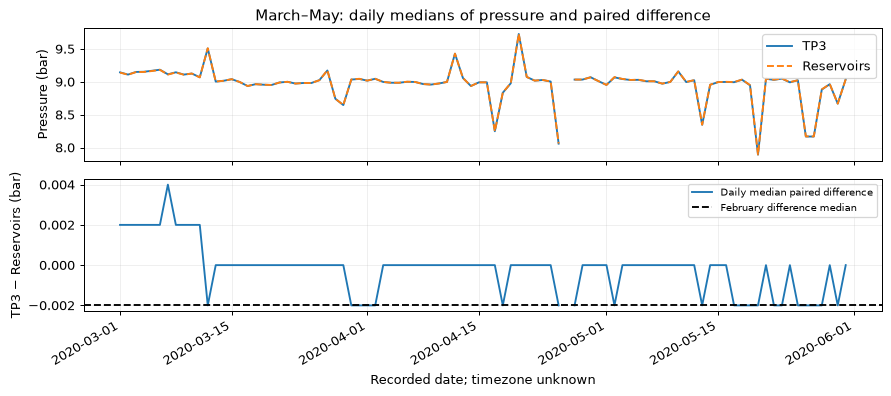

In [12]:
pressure = data[["timestamp", "entity_id"]].copy()
pressure["pressure_difference"] = data.TP3 - data.Reservoirs
pressure_reference = fit_reference(pressure, ["pressure_difference"], config["start"], config["train_end"], **fit_options)
pressure_evaluation = pressure.loc[pressure.timestamp.ge(config["train_end"])]
pressure_output = apply_reference(pressure_evaluation, pressure_reference, "pressure_difference")
pressure_output["month"] = pressure_output.timestamp.dt.to_period("M").astype(str)
pressure_report = compare_predictions({"difference": pressure_output}, ["month"])
pressure_reference.to_csv(OUTPUT / "pressure_reference.csv", index=False)
pressure_report.to_csv(OUTPUT / "pressure_comparison.csv", index=False)
pressure_output.to_csv(OUTPUT / "pressure_residuals.csv", index=False)
display(pressure_reference[["expected", "lower", "upper", "observations"]].round(5))
display(pressure_report.round(5))
display(Markdown(f"**Observed:** February's median TP3–Reservoirs difference is {pressure_reference.expected.iloc[0]:.4f} bar. "
                 f"Development mean residuals range from {pressure_report.bias.min():.4f} to {pressure_report.bias.max():.4f} bar. "
                 "These small offsets deserve calibration/measurement interpretation; near-perfect agreement cannot establish fault absence or independent sensing."))

pressure_view = development[["timestamp", "TP3", "Reservoirs"]].copy()
pressure_view["difference"] = pressure_output.observed.to_numpy()
daily = pressure_view.set_index("timestamp").resample("D").median()
fig, axes = plt.subplots(2, 1, figsize=(10, 4.5), sharex=True)
axes[0].plot(daily.index, daily.TP3, label="TP3")
axes[0].plot(daily.index, daily.Reservoirs, linestyle="--", label="Reservoirs")
axes[0].set(ylabel="Pressure (bar)", title="March–May: daily medians of pressure and paired difference")
axes[0].legend()
axes[1].plot(daily.index, daily.difference, label="Daily median paired difference")
axes[1].axhline(pressure_reference.expected.iloc[0], color="black", linestyle="--", label="February difference median")
axes[1].set(ylabel="TP3 − Reservoirs (bar)", xlabel="Recorded date; timezone unknown")
axes[1].legend(fontsize=8)
fig.autofmt_xdate(); fig.tight_layout(); plt.show()

## 8. Does the February reference transfer to March–May?

Compare by command and by calendar week rather than relying only on a pooled average. More frequent loading can change a whole-signal distribution without changing its conditional behaviour. Conversely, conditional references can conceal excessive loading; the command summaries above remain necessary.

Only the two development reports are overlaid below. Report intervals are not verified onset/impact times; observations outside them are not certified healthy. Coverage of empirical ranges is **not** an event recall or false-alarm statistic. No alert thresholds are selected here.

,measurement,method,availability,common,mae,bias,range_coverage,range_width
140,TP2,overall,1.0000,632232,1.4586,1.4553,0.8302,8.6000
141,TP2,command,0.9848,632232,0.2055,-0.1228,0.9227,0.8764
176,TP3,overall,1.0000,632232,0.5262,0.0520,0.8642,1.7360
177,TP3,command,0.9848,632232,0.5291,0.0301,0.8738,1.7553
212,H1,overall,1.0000,632232,1.9062,-1.3702,0.8322,9.8380
213,H1,command,0.9848,632232,0.4217,0.0716,0.8709,1.4241
248,DV_pressure,overall,1.0000,632232,0.1201,0.1119,0.4852,0.0080
249,DV_pressure,command,0.9848,632232,0.1201,0.1119,0.4852,0.0080
284,Reservoirs,overall,1.0000,632232,0.5254,0.0502,0.8645,1.7340
285,Reservoirs,command,0.9848,632232,0.5283,0.0286,0.8739,1.7530


,measurement,context,method,common,mae,bias,range_coverage
142,TP2,load_command,overall,106096,8.6373,8.6373,0.3235
143,TP2,load_command,command,106096,1.1701,-0.7667,0.8988
144,TP2,off_or_unloaded_command,overall,526136,0.0110,0.0070,0.9323
145,TP2,off_or_unloaded_command,command,526136,0.0110,0.0070,0.9275
146,TP2,unresolved,overall,0,NaN,NaN,NaN
147,TP2,unresolved,command,0,NaN,NaN,NaN
178,TP3,load_command,overall,106096,0.6638,-0.0499,0.6951
179,TP3,load_command,command,106096,0.6792,-0.2199,0.8059
180,TP3,off_or_unloaded_command,overall,526136,0.4985,0.0726,0.8983
181,TP3,off_or_unloaded_command,command,526136,0.4988,0.0806,0.8875


**Reference adequacy:** command references are available for 98.5% of native development observations. The fixed oil-temperature and dryer-pressure ranges cover only 50.4% and 48.5% of common development readings. February is useful for some relationships but is not a sufficient universal normal envelope. The data cannot separate all effects of demand, operating mix, sensor behaviour and faults.

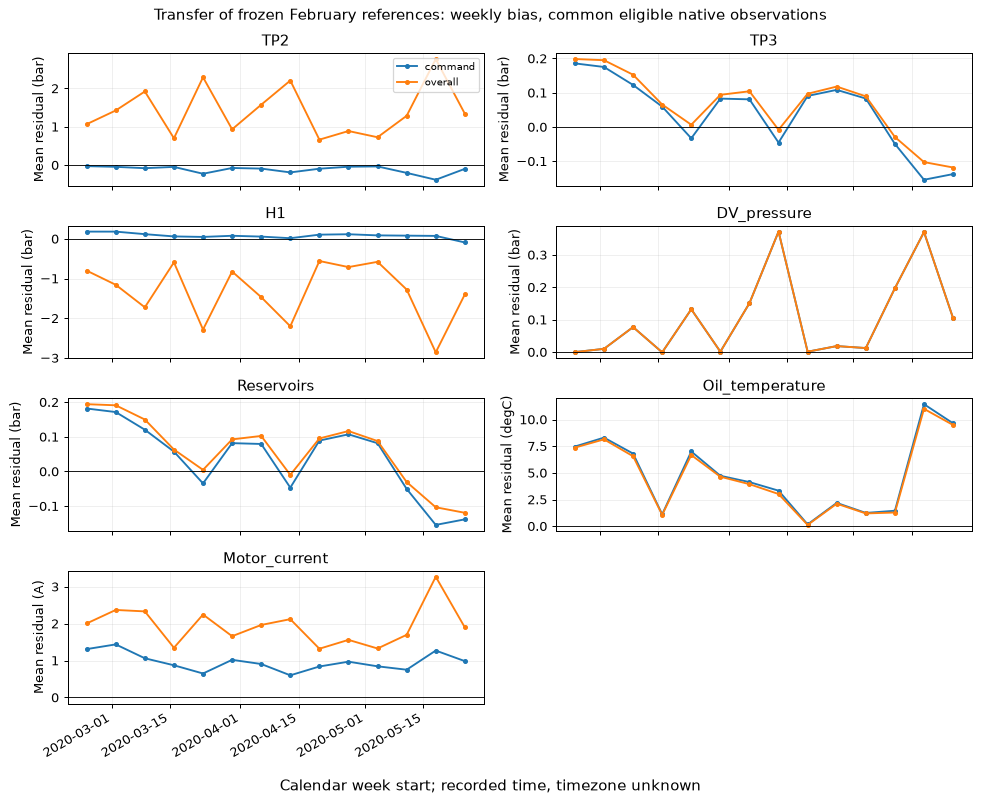

In [13]:
transfer = comparison.loc[comparison.period.eq("Development") & comparison.summary.eq("overall")]
display(transfer[["measurement", "method", "availability", "common", "mae", "bias", "range_coverage", "range_width"]].round(4))
state_transfer = comparison.loc[comparison.period.eq("Development") & comparison.summary.eq("by_command")]
display(state_transfer[["measurement", "context", "method", "common", "mae", "bias", "range_coverage"]].round(4))
context_availability = transfer.loc[transfer.method.eq("command"), "availability"].min()
coverage = transfer.pivot(index="measurement", columns="method", values="range_coverage")
display(Markdown(f"**Reference adequacy:** command references are available for {context_availability:.1%} of native development observations. "
                 f"The fixed oil-temperature and dryer-pressure ranges cover only {coverage.loc['Oil_temperature', 'overall']:.1%} and {coverage.loc['DV_pressure', 'overall']:.1%} of common development readings. "
                 "February is useful for some relationships but is not a sufficient universal normal envelope. The data cannot separate all effects of demand, operating mix, sensor behaviour and faults."))

weekly = comparison.loc[comparison.summary.eq("by_week") & comparison.period.eq("Development")]
fig, axes = plt.subplots(4, 2, figsize=(11, 9), sharex=True)
for ax, measurement in zip(axes.ravel(), analogue):
    for method, group in weekly.loc[weekly.measurement.eq(measurement)].groupby("method"):
        dates = pd.to_datetime(group.calendar_week.str.split("/").str[0])
        ax.plot(dates, group.bias, marker=".", label=method)
    ax.axhline(0, color="black", linewidth=.7)
    ax.set(title=measurement, ylabel=f"Mean residual ({METRICS[measurement].unit})")
axes.ravel()[-1].set_visible(False)
axes[0, 0].legend(fontsize=8)
fig.suptitle("Transfer of frozen February references: weekly bias, common eligible native observations")
fig.supxlabel("Calendar week start; recorded time, timezone unknown")
fig.autofmt_xdate(); fig.tight_layout(); plt.show()

,incident_id,start,end,source_issue
0,report_1,2020-04-18 00:00:00,2020-04-18 23:59:00,
1,report_2,2020-05-29 23:30:00,2020-05-30 06:00:00,Maintenance precedes reported incident; duplicate source report number #1.


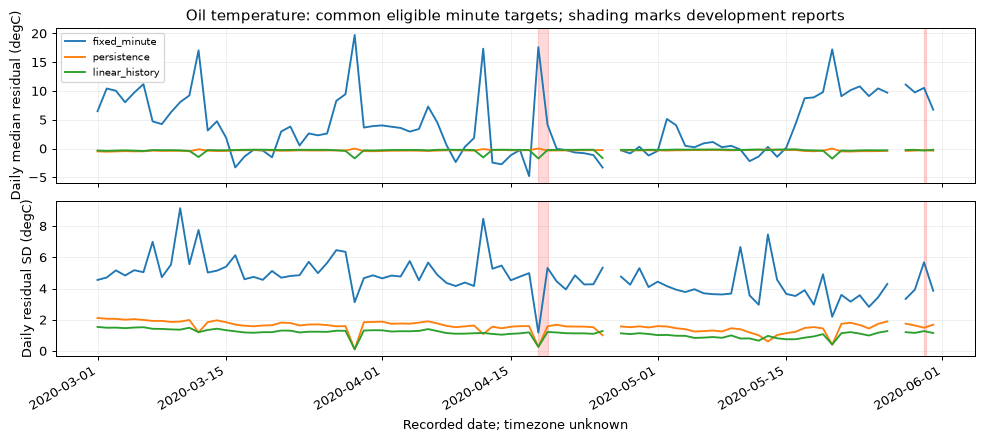

In [14]:
incidents = incident_records()
incidents = incidents.loc[incidents.start.ge(config["train_end"]) & incidents.end.lt(config["test_start"])].copy()
display(incidents[["incident_id", "start", "end", "source_issue"]])
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
common = np.logical_and.reduce([np.isfinite(frame.expected) & np.isfinite(frame.observed) for frame in temporal_predictions["Development"].values()])
for method, frame in temporal_predictions["Development"].items():
    paired = frame.assign(residual=frame.residual.where(common))
    daily_errors = paired.set_index("timestamp").resample("D")[["residual"]].agg(["median", "std"])
    axes[0].plot(daily_errors.index, daily_errors[("residual", "median")], label=method)
    axes[1].plot(daily_errors.index, daily_errors[("residual", "std")], label=method)
for ax in axes:
    for incident in incidents.itertuples():
        ax.axvspan(incident.start, incident.end, color="red", alpha=.15)
axes[0].set(title="Oil temperature: common eligible minute targets; shading marks development reports", ylabel="Daily median residual (degC)")
axes[1].set(ylabel="Daily residual SD (degC)", xlabel="Recorded date; timezone unknown")
axes[0].legend(fontsize=8)
fig.autofmt_xdate(); fig.tight_layout(); plt.show()

## 9. Handover to Notebook 03

Recommendations concern **baseline adequacy**, not demonstrated fault detection. We keep the fixed references when considering recent-history residuals, the original pressures when using their difference, and command behaviour when conditioning on commands. No assumption is made that lower MAE universally improves detection.

The recommendations below are explicit scientific judgements, with numerical evidence beside them. Tiny internal improvements are not treated as meaningful gains: pressure and temperature conditioning showed little benefit. Strong reductions for TP2, H1 and current justify carrying their command references forward. February is not silently redefined using later failures; no automatic model selector is created.

In [15]:
decisions = {
    "TP2": "Carry command reference alongside overall; inspect unsupported commands",
    "TP3": "Retain overall level and paired difference; command MAE gain is negligible",
    "H1": "Carry command reference alongside overall; remaining temporal structure matters",
    "DV_pressure": "Retain overall; sparse excursions and poor transfer need dryer context",
    "Reservoirs": "Retain overall level and paired difference; command MAE gain is negligible",
    "Oil_temperature": "Retain fixed level plus persistence; linear history is a mixed-result candidate",
    "Motor_current": "Carry command reference; pooled off/unloaded leaves substantial bias",
}
recommendations = []
development_mae = transfer.pivot(index="measurement", columns="method", values="mae")
for name, definition in METRICS.items():
    if name in analogue:
        decision = decisions[name]
        evidence_text = (f"February MAE change {improvement.loc[name, 'min']:.1%} to {improvement.loc[name, 'max']:.1%}; "
                         f"development overall/command MAE {development_mae.loc[name, 'overall']:.4f}/{development_mae.loc[name, 'command']:.4f} {definition.unit}")
    elif definition.role == "existing_alarm":
        decision, evidence_text = "Separate existing-alarm comparator", "Not an independent label or baseline predictor"
    elif definition.role == "unresolved":
        decision, evidence_text = "Defer numerical modelling", definition.note
    else:
        decision = "Keep command duration/transition checks" if name in ["COMP", "DV_eletric"] else "Keep as contextual diagnostic; no extra state combinations yet"
        evidence_text = "Monthly digital values and transition counts reported; observed state is not physical response"
    recommendations.append({"measurement": name, "role": definition.role, "evidence": evidence_text, "recommendation": decision})
handover = pd.DataFrame(recommendations)
display(handover)
handover.to_csv(OUTPUT / "notebook03_handover.csv", index=False)

,measurement,role,evidence,recommendation
0,TP2,measurement,February MAE change -88.6% to -87.8%; development overall/command MAE 1.4586/0.2055 bar,Carry command reference alongside overall; inspect unsupported commands
1,TP3,measurement,February MAE change -0.2% to -0.2%; development overall/command MAE 0.5262/0.5291 bar,Retain overall level and paired difference; command MAE gain is negligible
2,H1,measurement,February MAE change -55.8% to -50.8%; development overall/command MAE 1.9062/0.4217 bar,Carry command reference alongside overall; remaining temporal structure matters
3,DV_pressure,measurement,February MAE change 0.0% to 0.0%; development overall/command MAE 0.1201/0.1201 bar,Retain overall; sparse excursions and poor transfer need dryer context
4,Reservoirs,measurement,February MAE change -0.2% to -0.2%; development overall/command MAE 0.5254/0.5283 bar,Retain overall level and paired difference; command MAE gain is negligible
5,Oil_temperature,measurement,February MAE change -0.7% to -0.7%; development overall/command MAE 6.4740/6.6173 degC,Retain fixed level plus persistence; linear history is a mixed-result candidate
6,Motor_current,measurement,February MAE change -28.7% to -28.3%; development overall/command MAE 1.9437/1.0461 A,Carry command reference; pooled off/unloaded leaves substantial bias
7,COMP,context,Monthly digital values and transition counts reported; observed state is not physical response,Keep command duration/transition checks
8,DV_eletric,context,Monthly digital values and transition counts reported; observed state is not physical response,Keep command duration/transition checks
9,Towers,context,Monthly digital values and transition counts reported; observed state is not physical response,Keep as contextual diagnostic; no extra state combinations yet


In [16]:
# Compact reproducible outputs; full native observations are not duplicated on disk.
for (measurement, method), frame in example_predictions.items():
    frame.to_csv(OUTPUT / f"native_example_{measurement}_{method}.csv", index=False)
for method, frame in temporal_predictions["Development"].items():
    frame.to_csv(OUTPUT / f"minute_temperature_{method}.csv", index=False)
manifest = {"source": config["source"], "boundaries": folds.astype(str).to_dict("records"),
            "settings": settings, "source_max_used": str(data.timestamp.max()),
            "temporal_max_available": str(features.index.max()), "test_start": config["test_start"],
            "temporal_error_offsets": error_offsets,
            "code_sha256": {str(file.relative_to(ROOT)): sha256_file(file) for file in sorted((ROOT / "src/ts_anomaly").glob("*.py"))},
            "versions": {name: version(name) for name in ["numpy", "pandas", "matplotlib", "statsmodels"]}}
assert data.timestamp.max() < pd.Timestamp(config["test_start"])
# A bin available at the final-test boundary is deliberately excluded.
assert all(frame.timestamp.lt(config["test_start"]).all() for frame in temporal_predictions["Development"].values())
(OUTPUT / "manifest.json").write_text(json.dumps(manifest, indent=2) + "\n")
display(pd.Series(manifest["versions"], name="version").to_frame())
print("Final-test values remain protected. Model parameters, comparisons and example residuals saved in outputs/metropt_expected/.")

,version
numpy,2.3.5
pandas,2.3.3
matplotlib,3.11.2
statsmodels,0.14.6


Final-test values remain protected. Model parameters, comparisons and example residuals saved in outputs/metropt_expected/.


### Interpretation limits and next step

This is one asset, with incomplete incident evidence and unknown timezone. Quantile ranges are empirical descriptions, not alarm thresholds. Autocorrelation and changing variance limit IID interpretations; no row-level confidence intervals are claimed. Collection gaps and censored episodes limit duration and transition estimates. Binary command groups still pool off and unloaded operation. History models can follow faults, and the pressure difference can miss shared pressure loss.

Notebook 03 should use the selected **candidate residual channels and command summaries** to study calibration, persistence and operational alert burden. It must preserve the final-test boundary, distinguish report-free from known-healthy observations, and assess event timing separately from prediction error. No detection accuracy or early-warning capability has been established here.

References: [2020 UCI source](https://doi.org/10.24432/C5VW3R); [time-series validation](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-of-time-series-data); [forecast residual diagnostics and chronological evaluation](https://otexts.com/fpp3/toolbox.html). The empirical choices and limitations of this particular experiment are documented above rather than presented as universal defaults.